<a href="https://colab.research.google.com/github/MOHAMEDAAKIFASRAR/TSA_EXP9/blob/main/TSA_EXP9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

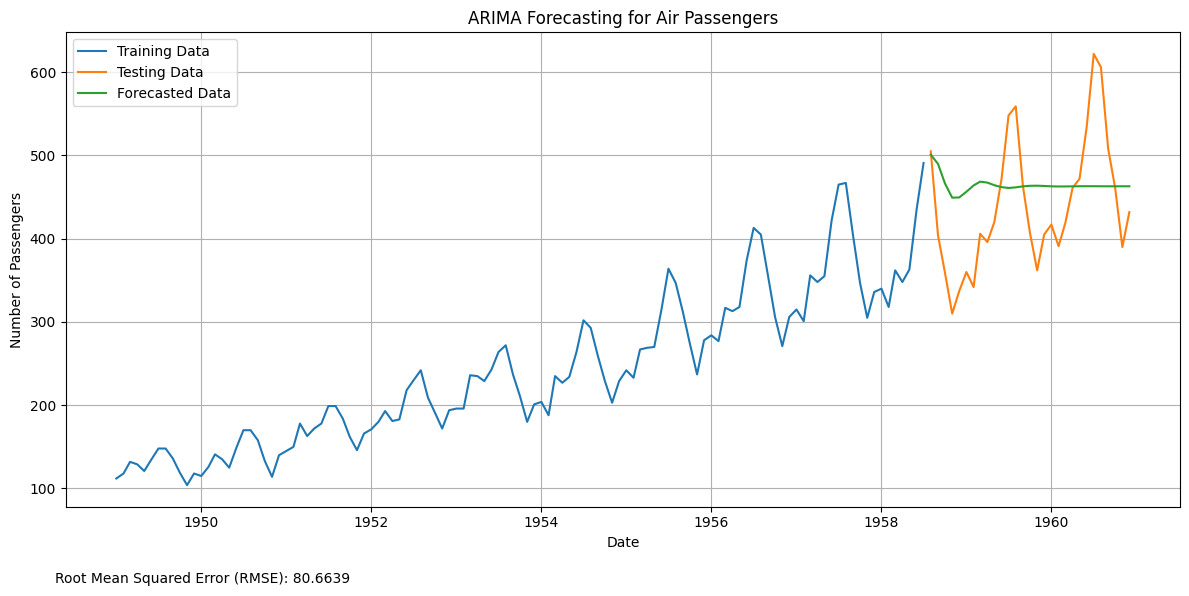

Root Mean Squared Error (RMSE): 80.66394527011326


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error

# Load AirPassengers dataset
data = pd.read_csv("/content/AirPassengers.csv")

# Convert Month column to datetime
data['Month'] = pd.to_datetime(data['Month'], format='%Y-%m')

# Set Month as index
data.set_index('Month', inplace=True)
data.sort_index(inplace=True)

# Extract passenger data
data = data['#Passengers'].asfreq('MS')

# ARIMA Model
def arima_model(data, order):

    train_size = int(len(data) * 0.8)

    train_data = data[:train_size]
    test_data = data[train_size:]

    model = ARIMA(train_data, order=order)
    fitted_model = model.fit()

    forecast = fitted_model.forecast(steps=len(test_data))

    rmse = np.sqrt(
        mean_squared_error(test_data, forecast)
    )

    # Plot actual and predicted data
    plt.figure(figsize=(12, 6))

    plt.plot(
        train_data.index,
        train_data,
        label='Training Data'
    )

    plt.plot(
        test_data.index,
        test_data,
        label='Testing Data'
    )

    plt.plot(
        test_data.index,
        forecast,
        label='Forecasted Data'
    )

    plt.xlabel('Date')
    plt.ylabel('Number of Passengers')

    plt.title('ARIMA Forecasting for Air Passengers')

    plt.legend()
    plt.grid()

    plt.figtext(
        0.05, 0.02,
        f"Root Mean Squared Error (RMSE): {rmse:.4f}"
    )

    plt.tight_layout(rect=[0, 0.05, 1, 1])

    plt.show()

    print("Root Mean Squared Error (RMSE):", rmse)


# Call the function
arima_model(data, order=(5, 1, 0))
